In [1]:
import re
from collections import Counter

import requests
import pandas as pd

import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.util import ngrams

import matplotlib.pyplot as plt
from wordcloud import WordCloud

nltk.download("stopwords", quiet=True)
nltk.download("punkt_tab", quiet=True)

plt.rcParams["figure.dpi"] = 110

In [2]:
URL = "https://www.gutenberg.org/cache/epub/83/pg83.txt"

response = requests.get(URL)
response.encoding = "utf-8"
raw_file = response.text
raw_file = raw_file.replace("\r\n", "\n")
print("HTTP durum kodu:", response.status_code)

print("Dosyanın tamamı:", len(raw_file), "karakter")

# Gutenberg başlık ve lisans kısmını ayırma
start = re.search(r"\*\*\* START OF THE PROJECT GUTENBERG EBOOK .*? \*\*\*", raw_file)
end = re.search(r"\*\*\* END OF THE PROJECT GUTENBERG EBOOK .*? \*\*\*", raw_file)
book = raw_file[start.end():end.start()]

print("Sadece kitap metni:", len(book), "karakter")
print("-" * 60)
print(book[:600])

HTTP durum kodu: 200
Dosyanın tamamı: 564078 karakter
Sadece kitap metni: 544710 karakter
------------------------------------------------------------


[Illustration]




From the Earth to the Moon

by Jules Verne


Contents: From the Earth to the Moon

 CHAPTER I. The Gun Club
 CHAPTER II. President Barbicane’s Communication
 CHAPTER III. Effect of the President’s Communication
 CHAPTER IV. Reply From the Observatory of Cambridge
 CHAPTER V. The Romance of the Moon
 CHAPTER VI. The Permissive Limits of Ignorance and Belief in the United States
 CHAPTER VII. The Hymn of the Cannon-Ball
 CHAPTER VIII. History of the Cannon
 CHAPTER IX. The Question of the Powders
 CHAPTER X. One Enemy _v._ Twenty-Five Millions of Friends
 CHAPTER XI. Florida


In [3]:
text = book.lower() # küçük harf
text = re.sub(r'[^\w\s]', ' ', text)      # noktalama ve özel karakterler
text = re.sub(r'\d+', ' ', text)          # sayılar
text = re.sub(r'_', ' ', text)            # _italik_ işaretleri
text = re.sub(r'\s+', ' ', text).strip()  # fazla boşluklar

print(text[:400])

illustration from the earth to the moon by jules verne contents from the earth to the moon chapter i the gun club chapter ii president barbicane s communication chapter iii effect of the president s communication chapter iv reply from the observatory of cambridge chapter v the romance of the moon chapter vi the permissive limits of ignorance and belief in the united states chapter vii the hymn of 


In [4]:
tokens_all = word_tokenize(text) # tokenization
print("Tokenizer çıktısı:", len(tokens_all), "token")
print(tokens_all[:30])

Tokenizer çıktısı: 92039 token
['illustration', 'from', 'the', 'earth', 'to', 'the', 'moon', 'by', 'jules', 'verne', 'contents', 'from', 'the', 'earth', 'to', 'the', 'moon', 'chapter', 'i', 'the', 'gun', 'club', 'chapter', 'ii', 'president', 'barbicane', 's', 'communication', 'chapter', 'iii']


In [5]:
MIN_LEN = 3 # kısa token ekleme
raw_tokens = [t for t in tokens_all if len(t) >= MIN_LEN]

print("Kısa token eleme sonrası (ham token):", len(raw_tokens))
print("Elenen kısa token:", len(tokens_all) - len(raw_tokens)) # eleme

Kısa token eleme sonrası (ham token): 73362
Elenen kısa token: 18677


In [6]:
stop_words = set(stopwords.words("english")) # stop words
print("Stop words listesi:", len(stop_words), "kelime")

clean_tokens = [t for t in raw_tokens if t not in stop_words]

reduction = (len(raw_tokens) - len(clean_tokens)) / len(raw_tokens) * 100
print("Temiz token:", len(clean_tokens))
print(f"Stop words azalması: %{reduction:.1f}")

Stop words listesi: 198 kelime
Temiz token: 45954
Stop words azalması: %37.4


In [7]:
stemmer = PorterStemmer() # stemming
stems = [stemmer.stem(t) for t in clean_tokens]

print("Benzersiz kelime (temiz):", len(set(clean_tokens)))
print("Benzersiz kök (stem):    ", len(set(stems)))
for w in ["travelers", "projectile", "calculations", "moon", "replied"]:
    print(f"  {w:13} -> {stemmer.stem(w)}")

Benzersiz kelime (temiz): 7903
Benzersiz kök (stem):     5345
  travelers     -> travel
  projectile    -> projectil
  calculations  -> calcul
  moon          -> moon
  replied       -> repli


In [9]:
freq_with = Counter(raw_tokens) # frekans
freq_without = Counter(clean_tokens)

top20_with = freq_with.most_common(20) # en sık 20 kelime, stopwords ile
top20_without = freq_without.most_common(20) # en sık 20 kelime, stopwords olmadan

df_top20 = pd.concat([pd.DataFrame(top20_with, columns=["Stop words İLE", "Frekans"]),
                      pd.DataFrame(top20_without, columns=["Stop words OLMADAN", "Frekans "])], axis=1)
df_top20.index = range(1, 21)
df_top20

,Stop words İLE,Frekans,Stop words OLMADAN,Frekans
1,the,7799,barbicane,568
2,and,2024,moon,464
3,that,1048,projectile,436
4,was,971,would,411
5,not,777,michel,407
6,which,728,one,378
7,with,630,said,323
8,this,609,nicholl,276
9,they,595,ardan,265
10,barbicane,568,earth,260


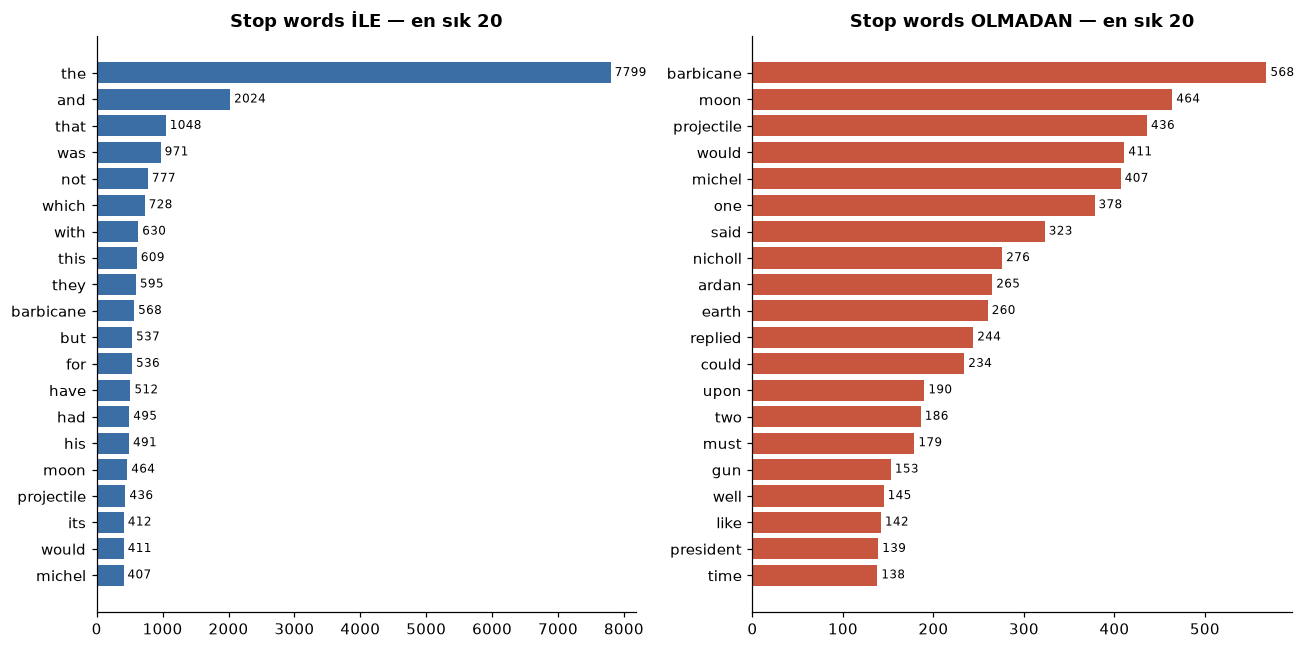

In [10]:
def barh(ax, pairs, color, title):
    words = [w for w, _ in pairs][::-1]
    counts = [c for _, c in pairs][::-1]
    ax.barh(words, counts, color=color)
    for y, c in enumerate(counts):
        ax.text(c, y, f" {c}", va="center", fontsize=8)
    ax.set_title(title, fontweight="bold")
    ax.spines[["top", "right"]].set_visible(False)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
barh(axes[0], top20_with, "#3a6ea5", "Stop words İLE — en sık 20")
barh(axes[1], top20_without, "#c8553d", "Stop words OLMADAN — en sık 20")
plt.tight_layout()
plt.show()

In [11]:
bigram_freq = Counter(ngrams(clean_tokens, 2))
trigram_freq = Counter(ngrams(clean_tokens, 3))

top15_bi = bigram_freq.most_common(15) # en sık 15 bigram
top10_tri = trigram_freq.most_common(10) # 10 trigram

df_bi = pd.DataFrame([(" ".join(g), c) for g, c in top15_bi], columns=["Bigram", "Frekans"], index=range(1, 16))
df_tri = pd.DataFrame([(" ".join(g), c) for g, c in top10_tri], columns=["Trigram", "Frekans"], index=range(1, 11))

print("En sık 15 bigram")
display(df_bi)
print("En sık 10 trigram")
display(df_tri)

En sık 15 bigram


,Bigram,Frekans
1,michel ardan,210
2,gun club,109
3,replied barbicane,86
4,said michel,78
5,said barbicane,64
6,said nicholl,53
7,exclaimed michel,47
8,president barbicane,43
9,replied michel,42
10,replied nicholl,29


En sık 10 trigram


,Trigram,Frekans
1,said michel ardan,30
2,exclaimed michel ardan,26
3,members gun club,19
4,president gun club,17
5,replied michel ardan,17
6,secretary gun club,11
7,minutes past ten,10
8,yards per second,8
9,velocity yards per,7
10,nine feet diameter,7


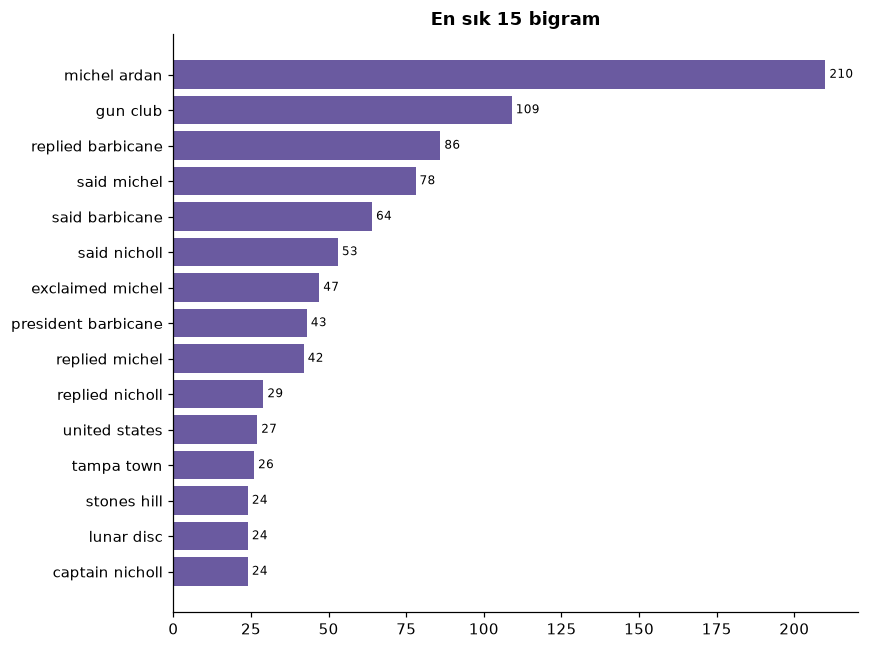

In [12]:
fig, ax = plt.subplots(figsize=(8, 6))
barh(ax, [(" ".join(g), c) for g, c in top15_bi], "#6a5aa0", "En sık 15 bigram")
plt.tight_layout()
plt.show()

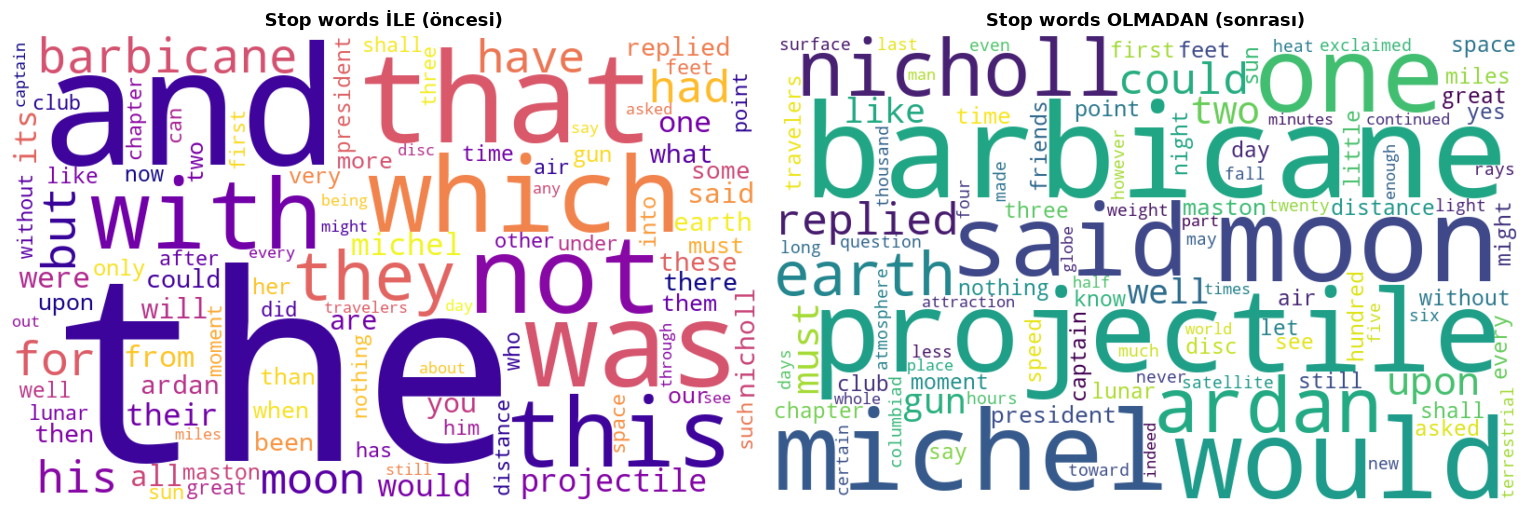

In [13]:
wc_before = WordCloud(width=800, height=500, max_words=100, background_color="white",
                      colormap="plasma", random_state=42).generate_from_frequencies(freq_with)
wc_after = WordCloud(width=800, height=500, max_words=100, background_color="white",
                     colormap="viridis", random_state=42).generate_from_frequencies(freq_without)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, wc, title in [(axes[0], wc_before, "Stop words İLE (öncesi)"),
                      (axes[1], wc_after, "Stop words OLMADAN (sonrası)")]:
    ax.imshow(wc, interpolation="bilinear")
    ax.set_title(title, fontweight="bold")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [14]:
n_chars = len(book)
avg_len = sum(len(t) for t in clean_tokens) / len(clean_tokens)

df_stats = pd.DataFrame({
    "Değer": [n_chars, len(raw_tokens), len(clean_tokens),
              len(set(raw_tokens)), len(set(clean_tokens)), len(set(stems)),
              f"%{reduction:.1f}", f"{avg_len:.2f}"]
}, index=["Karakter (kitap metni)", "Ham token (stop words ile)", "Temiz token (stop words yok)",
          "Benzersiz kelime — ile", "Benzersiz kelime — olmadan", "Benzersiz kök (stem)",
          "Stop words azalması", "Ortalama kelime uzunluğu (harf)"])
df_stats

,Değer
Karakter (kitap metni),544710
Ham token (stop words ile),73362
Temiz token (stop words yok),45954
Benzersiz kelime — ile,8006
Benzersiz kelime — olmadan,7903
Benzersiz kök (stem),5345
Stop words azalması,%37.4
Ortalama kelime uzunluğu (harf),6.45


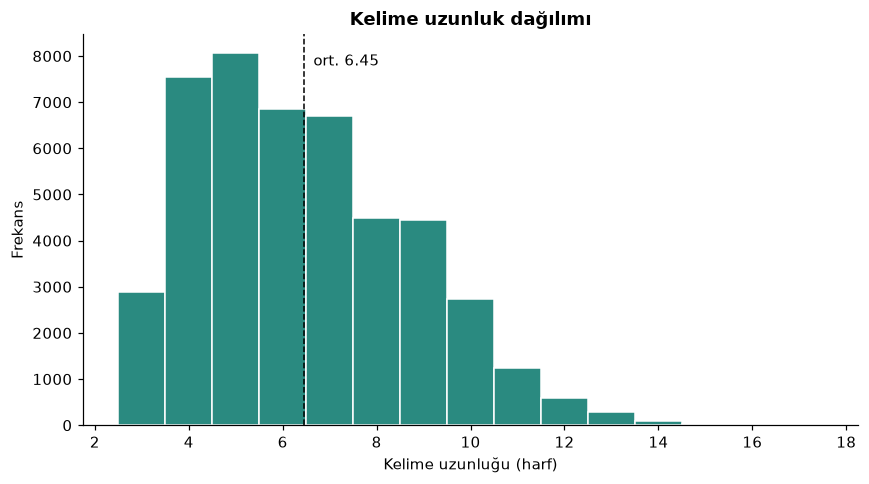

Uzunluk (harf),3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
Adet,2888,7538,8070,6859,6697,4487,4447,2736,1248,587,278,83,28,7,1


In [15]:
lengths = [len(t) for t in clean_tokens]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(lengths, bins=range(MIN_LEN, max(lengths) + 2), color="#2a8a80", edgecolor="white", align="left")
ax.axvline(avg_len, color="black", linestyle="--", linewidth=1)
ax.text(avg_len + 0.2, ax.get_ylim()[1] * 0.92, f"ort. {avg_len:.2f}")
ax.set_xlabel("Kelime uzunluğu (harf)")
ax.set_ylabel("Frekans")
ax.set_title("Kelime uzunluk dağılımı", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

df_len = pd.Series(lengths).value_counts().sort_index().rename_axis("Uzunluk (harf)").to_frame("Adet")
df_len.T

**Grafikler kitap hakkında ne söylüyor?**

Stop words çıkarılınca the, and, that yerini barbicane, moon, projectile alıyor; kitap, Ay'a gönderilecek bir mermi ve onu tasarlayanlar etrafında dönüyor. Bigram ve trigramlar ana kahramanları (Michel Ardan, President Barbicane, Captain Nicholl), Gun Club'ı ve fırlatma yeri Tampa Town / Stones Hill'i doğrudan ortaya çıkarıyor. said/replied/exclaimed + isim kalıpları, olayların büyük ölçüde bu üç kahramanın diyaloglarıyla ilerlediğini gösteriyor. yards per second, nine feet diameter gibi ölçü ifadeleri ve 6,45 harflik ortalama kelime uzunluğu, Verne'in hesaplara dayanan teknik ve bilimsel bir dil kullandığını gösteriyor.